# Imports

In [1]:
import matplotlib.pyplot as plt
import torch, gc
import torch.nn.functional as F
from torch.func import functional_call, vmap, grad
from torch.utils.data import DataLoader
from transformers import DataCollatorForLanguageModeling
import math
from itertools import chain
from tqdm import tqdm
from transformers import GPTNeoXForCausalLM, AutoTokenizer, AutoModelForCausalLM
import numpy as np
import wandb
from torch.autograd.functional import jvp

/home/ishitak/envs/mem/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Model

In [2]:
gc.collect()
torch.cuda.empty_cache()
device = torch.device("cuda:0")

model = AutoModelForCausalLM.from_pretrained(
  "Qwen/Qwen2.5-1.5B",
  cache_dir="./qwen25_15b",
)

tokenizer = AutoTokenizer.from_pretrained(
  "Qwen/Qwen2.5-1.5B",
  cache_dir="./qwen25_15b",
)

tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = tokenizer.eos_token_id
model.to(device)

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 7876.67it/s]


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotar

In [3]:
from torchvision import datasets #To load dataset
from datasets import DatasetDict, Dataset
from datasets import load_dataset
import pandas as pd
import kagglehub

# Load the dataset
def get_dataset(ratio=0.004):
    path = kagglehub.dataset_download("wcukierski/enron-email-dataset")
    dataset_all = load_dataset("csv", data_files=f"{path}/emails.csv", split="train")
    sub_dataset = dataset_all.select(range(int(ratio * len(dataset_all)))) # no shuffling. Exact same examples selected every time

    split_ratio = 0.1 
    train_test_split = sub_dataset.train_test_split(test_size=split_ratio, seed=42)

    dataset = DatasetDict({
        'train': train_test_split['train'],
        'validation': train_test_split['test']
    })
    return dataset

In [4]:
def extract_text(msg):
    # Split headers and body
    parts = msg.split("\n\n", 1)
    headers = parts[0]
    body = parts[1] if len(parts) > 1 else msg

    # Default subject if not found
    subject = ""

    for line in headers.splitlines():
        if line.lower().startswith("subject:"):
            subject = line[len("subject:"):].strip()
            break

    # Combine into one text field
    return f"Subject: {subject}\n\n{body}"

# Apply to train
def prep_dataset(dataset):
    train_df = pd.DataFrame(dataset["train"])
    train_df["text"] = train_df["message"].apply(extract_text)
    train_df = train_df.drop(columns=["file", "message"])

    # Apply to validation
    val_df = pd.DataFrame(dataset["validation"])
    val_df["text"] = val_df["message"].apply(extract_text)
    val_df = val_df.drop(columns=["file", "message"])

    dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df)  # assuming you have valid_df
    })
    return dataset

# Preprocessing Data

### Tokenization

In [5]:
def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, return_special_tokens_mask=True)

In [6]:
def get_canary_tokens(canary):
    input_ids=tokenizer(canary,truncation=True,return_special_tokens_mask=True)
    print(input_ids)
    return input_ids

In [7]:
def get_example_indices(total,num,shuffle=False):
    if shuffle==True:
        return np.random.choice(total, size=num, replace=False)
    else:
        return np.arange(0,num)

### Grouping into Blocks

In [8]:
block_size=256
run=True
def group_texts(examples,canary,num,shuffle):
    # Concatenate all texts.
    global run 
    concatenated_examples = {k: list(chain(*examples[k])) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    # We drop the small remainder, and if the total_length < block_size  we exclude this batch and return an empty dict.
    # We could add padding if the model supported it instead of this drop, you can customize this part to your needs.
    total_length = (total_length // block_size) * block_size
    # Split by chunks of max_len.
    result = {
        k: [t[i : i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated_examples.items()
    }
    print(total_length//block_size)

    if(total_length//block_size>1000):
        print("called")
        result["indicators"] = [0 for _ in range(total_length//block_size)]
        ind=get_example_indices(total_length//block_size,num,shuffle)
        print(ind)
        ans=get_canary_tokens(canary=canary)
        print(ans['input_ids'])
        length=len(ans['input_ids'])
        for j in ind:
            for key in result.keys():
                if(key=="indicators"):
                    continue
                for i in range(length):
                    result[key][j][i]=ans[key][i]
            result["indicators"][j]=1
        run=False
    else:
        run=True
    result["labels"] = result["input_ids"].copy()
    return result

# Dataloaders

In [9]:
def get_dataloaders(tokenized_datasets,per_device_train_batch_size,per_device_eval_batch_size,sub_batch_size):
    train_dataset = tokenized_datasets["train"]
    train_dataset = train_dataset.select(range((len(train_dataset)//per_device_train_batch_size)*per_device_train_batch_size))
    eval_dataset = tokenized_datasets["validation"]
    data_collator = DataCollatorForLanguageModeling(
        tokenizer=tokenizer, mlm=False
    )
    train_dataloader = DataLoader(
        train_dataset, shuffle=False, collate_fn=data_collator, batch_size=sub_batch_size
    )
    eval_dataloader = DataLoader(
        eval_dataset, collate_fn=data_collator, batch_size=per_device_eval_batch_size
    )
    return train_dataloader,eval_dataloader

# Calculating no. of steps

In [10]:
def get_steps(train_dataloader,max_train_steps=None,num_train_epochs=1):    
    num_update_steps_per_epoch = math.ceil(len(train_dataloader)) # per epoch training steps = len(train_dataloader)
    if max_train_steps is None:
        max_train_steps = num_train_epochs * num_update_steps_per_epoch # total number of training steps = no. of epochs*per epoch training steps
    print(f'No. of Training Steps = {max_train_steps}')
    print(f'No. of update steps per epoch = {num_update_steps_per_epoch}')

    return num_update_steps_per_epoch,max_train_steps

# Calculating Per Example Gradients

## Loss & Grad of Loss

In [11]:
#Computing per example gradients
def loss_fn(predictions, targets):
    return F.cross_entropy(predictions, targets,reduction='mean')

def compute_loss(params, buffers, train_data,labels):
    train_data=train_data.unsqueeze(0)
    t = functional_call(model, (params, buffers), (train_data,)) 
    # print(f'predictions = {predictions}')# CausalLMOutputWithPast (loss, logits, past key values)
    # print(f'ptred={predictions.logits.shape}')# [1, 256, 50257]
    t=t.logits.squeeze(0)
    labels=labels.squeeze(0)
    t = torch.narrow(t, dim=0, start=0, length=t.size(0)-1)
    labels = torch.narrow(labels, dim=0, start=1, length=labels.size(0)-1)
    # print(f'token pred shape={t.shape}') # [256, 50257]
    # print(f'token pred={t}')
    # print(f'labels shape={labels.shape}') # [256]
    # print(f'labels={labels}')
    loss = loss_fn(t, labels)
    # print(loss)
    return loss

ft_compute_grad = grad(compute_loss)
ft_compute_sample_grad = vmap(ft_compute_grad, in_dims=(None, None, 0, 0))
ft_compute_loss = vmap(compute_loss, in_dims=(None, None, 0, 0))

## Norm

In [12]:
# takes in per example gradients dictionary and computes the norm
def get_norm(per_ex_grad):
    norm=0
    for i in list(per_ex_grad.values()):
        dim = i.size(0)
        i=i.reshape(dim,-1)
        norm+=(torch.norm(i,dim=1))**2
    return (norm)**0.5
#returns norm vector of size b (batch size)

## Clipped Grads

In [13]:
#Takes in the per example grad (dict) as well as the norm (vector) and computes the clipped grad
def get_clip(norm, per_ex_grad):
    v=10**(-6)
    C=1
    o = torch.ones(norm.size()).to(device)
    norm=C/(norm+v)
    coeff = torch.minimum(o,norm)
    
    for key in per_ex_grad.keys():
        if len(per_ex_grad[key].shape)==2:
            coeff=coeff.view(-1,1)
        else: coeff=coeff.view(-1,1,1)
        per_ex_grad[key] = torch.mul(per_ex_grad[key],coeff) 
    
    return per_ex_grad
#returns the clipped grad -> dict (same as the size of per example grad)

# Accuracy

In [14]:
def evaluate_model(dataloader):    
    model.eval()
    t_loss_sum = 0  # Sum of validation losses for the epoch
    total_t_correct = 0
    total_t_samples = 0

    with torch.no_grad():
        for step,batch in enumerate(dataloader):
            batch = {k: v.to(device) for k, v in batch.items()}
            batch['input_ids']=batch['input_ids'].long()
            batch['labels']=batch['labels'].long()
            outputs = model(**batch)
            t_loss_sum += outputs.loss.item()

            # Get predictions and calculate validation accuracy
            pred = torch.argmax(outputs.logits, dim=2)
            label = batch["labels"]
            preds = torch.narrow(pred, dim=1, start=0, length=pred.size(1)-1)
            labels = torch.narrow(label, dim=1, start=1, length=label.size(1)-1)
            total_t_correct += (preds == labels).sum().item()
            total_t_samples +=  (labels==labels).sum().item()
            
            # print(f'batch={batch["input_ids"]}')
            # print(f'preds={preds}')
            # print(f'labels={labels}')
            # print(f'correct={total_t_correct}')
            # print(f'total={total_t_samples}')

    # Calculate average validation loss and accuracy for the epoch
    # avg_t_loss = t_loss_sum / len(dataloader)
    # t_perplexity = math.exp(avg_t_loss)
    t_accuracy = total_t_correct / total_t_samples

    # print(f""
        # f"Average Loss = {avg_t_loss:.4f}, Accuracy = {t_accuracy * 100:.2f}%, ")
        # f"Train Perplexity = {t_perplexity:.2f}")
    
    return (t_accuracy*100)

# FIL

In [15]:
def get_norm_FIL(grads):
    return torch.sqrt(sum(g.norm()**2 for g in grads))

def get_clip_FIL(norm, grads, C=1.0):
    scale = min(1.0, C / (norm + 1e-6))
    return [g * scale for g in grads]
    
def f(embeddings,labels):
    embeddings = embeddings.requires_grad_(True) #[256,768]
    sample_batch = embeddings.unsqueeze(0) if embeddings.dim() == 2 else embeddings # Adding a batch dimension if not present
    outputs = model(inputs_embeds=sample_batch, labels=labels.long())
    loss = outputs.loss
    grads = torch.autograd.grad(loss, model.parameters(), create_graph=True)
    norms = get_norm_FIL(grads)
    clip = get_clip_FIL(norms,grads)
    flat_grads = torch.cat([g.flatten() for g in clip])
    return flat_grads

In [16]:
from torch.backends.cuda import sdp_kernel, SDPBackend
def get_FIL(sigma,z):
    num=50
    cum=0
    l = z.unsqueeze(0).float()
    v_label = torch.zeros_like(l)  
    with torch.no_grad():
        base_embed = model.get_input_embeddings()(z)
    base_embed = base_embed.detach().requires_grad_(True)

    with sdp_kernel(enable_flash=False, enable_math=True, enable_mem_efficient=False):
        for i in range(num):
            v = torch.randn_like(base_embed)
            _, jvp_grad = jvp(f, (base_embed,l), (v,v_label))
            jvp_grad_norm=torch.norm(jvp_grad)**2
            cum+=jvp_grad_norm 
    cum=cum/num

    return cum/(sigma**2)

# Training

In [17]:
#DP-SGD Update
def get_clip2(params, input_ids,labels):

    #compute per example gradients
    ft_per_sample_grads = ft_compute_sample_grad(params,{},input_ids,labels)
    # for key, value in ft_compute_sample_grad(params,{},input_ids,labels).items():
    #     clip[key]+=torch.sum(value,dim=0)
    # clip=ft_per_sample_grads
    # #compute norm of per example gradients
    norm = get_norm(ft_per_sample_grads)

    # #compute the clipped gradient -> dict
    clip=get_clip(norm,ft_per_sample_grads)

    for key in clip.keys():
        clip[key] = torch.sum(clip[key],dim=0)
    # print("\nstatement:2")
    return clip

In [18]:
#Training the model
import bitsandbytes as bnb

def train_model(r,canary,train_dataloader, eval_dataloader, learning_rate,num_epoch,T,batch_size,sub_batch_size,n,sigma,ep):
    test_canary='Dear Ram, \nThe last four digits of my credit card number are 9837'
    test_can_tokens=get_canary_tokens(test_canary)
    input_test_canary=test_can_tokens['input_ids']

    params = {k: v.detach() for k, v in model.named_parameters()}
    weight_decay = 0.01
    no_decay = ["bias", "layer_norm.weight"]
    optimizer_grouped_parameters = [
        {
            "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            "weight_decay": weight_decay,
        },
        {
            "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            "weight_decay": 0.0,
        },
    ]
    optimizer = bnb.optim.AdamW8bit(optimizer_grouped_parameters, lr=learning_rate)
    base_fil=[]
    fil=[]
    cp=int(T*sub_batch_size/batch_size)
    progress_bar = tqdm(range(cp))
    completed_steps = 0
    # exposure=get_exposure(canary=canary,n_dash=3)
    # wandb.log({'Exposure':exposure, 'Epoch':0.0},step=completed_steps)
    # acc=evaluate_model(dataloader=eval_dataloader)
    # wandb.log({'Validation accuracy':acc,'Epoch':0.0},step=completed_steps)
   
    myy_fil = 0
    myy_base_fil = 0
    ind=0
    print(f"FIL={myy_fil}, Baseline FIL={myy_base_fil} for step={ind}")
    # base_fil.append((myy_base_fil,ind))
    fil.append((myy_fil,ind))
    for epoch in range(num_epoch):
        model.train()
        clip = {k: torch.zeros_like(v.detach()) for k, v in model.named_parameters()}
        for step, batch in enumerate(train_dataloader):
            # if step==0:
                # print(f"batch:{batch['input_ids']}")
            # print(f'step={step}')
            batch = {k: v.to(device) for k, v in batch.items()}
            for key, value in get_clip2(params,batch["input_ids"],batch["labels"]).items():
                clip[key]+=value
            # get_clip2(params=params,input_ids=batch["input_ids"],labels=batch["labels"],sigma=sig,clip=clip)

            for i in range(len(batch['indicators'])):
                if batch['indicators'][i].item()==1:
                    # print(batch['input_ids'][i])
                    ind+=1
                    my_fil = get_FIL(sigma,batch['input_ids'][i])
                    myy_fil+=my_fil
                    fil.append((myy_fil.item(),ind))

                    # baseline=batch['input_ids'][i].clone()
                    # for g in range(len(input_test_canary)):
                        # baseline[g]=input_test_canary[g]
                    # print(baseline)
                    # my_baseline_fil=get_FIL(sigma,baseline)
                    # myy_base_fil+=my_baseline_fil
                    print(f"FIL={myy_fil}, Baseline FIL={myy_base_fil} for step={ind}")
                    # base_fil.append((myy_base_fil.item(),ind))

            if (step+1)%(batch_size/sub_batch_size)==0:  
                # print(f'update {(step+1)*sub_batch_size/batch_size}')      
                for p,key in zip(model.parameters(),clip.keys()):
                    s=clip[key].shape
                    clip[key]+=torch.normal(mean=torch.zeros(s).to(device), std=sigma*torch.ones(s).to(device)).to(device)
                    clip[key]=torch.div(clip[key],batch_size)
                    p.grad=clip[key]
                
                clip = {k: torch.zeros_like(v.detach()) for k, v in model.named_parameters()}
                # print('refreshed')
                optimizer.step()
                optimizer.zero_grad()
                
                loss = ft_compute_loss(params,{}, batch["input_ids"], batch["labels"])
                loss=torch.mean(loss).item()
                wandb.log({'Training Loss':loss,'Epoch':completed_steps/cp*num_epoch},step=completed_steps)
                params = {k: v.detach() for k, v in model.named_parameters()}
                progress_bar.update(1)
                completed_steps += 1    


                # if completed_steps%(int(0.01*r*cp/num_epoch))==0:# logs every r% in each epoch
                #     exposure=get_exposure(canary=canary,n_dash=3)
                #     wandb.log({'Exposure':exposure, 'Epoch':completed_steps/cp*num_epoch},step=completed_steps)

                if completed_steps%(int(0.25*cp/num_epoch))==0:# logs for every 25% in each epoch
                    acc=evaluate_model(dataloader=eval_dataloader)
                    wandb.log({'Validation accuracy':acc,'Epoch':completed_steps/cp*num_epoch},step=completed_steps)
    
    loss = ft_compute_loss(params,{}, batch["input_ids"], batch["labels"])
    loss=torch.mean(loss).item()
    wandb.log({'Training Loss':loss,'Epoch':completed_steps/cp*num_epoch},step=completed_steps)

    return fil,base_fil

# Noise

In [19]:
from scipy import optimize as opt
from dp_accounting import dp_event as event
from dp_accounting.rdp import rdp_privacy_accountant as rdp

#Computing noise multipler
def get_noise_multiplier(target_epsilon, target_delta, sampling, step):
    RDP_ORDERS = (
        [1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 3.0, 3.5, 4.0, 4.5]
        + list(range(5, 64))
        + [128, 256, 512]
    )
    def objective(noise_multiplier):
        accountant = rdp.RdpAccountant(RDP_ORDERS)
        dpevent = event.SelfComposedDpEvent(
            event.PoissonSampledDpEvent(
                sampling, event.GaussianDpEvent(noise_multiplier)
            ),
            step,
        )
        accountant.compose(dpevent)
        eps = accountant.get_epsilon(target_delta)
        return eps - target_epsilon

    optimal_noise = opt.brentq(objective, 1e-6, 1000)
    return optimal_noise

def get_sigma(T,n,batch_size,ep):
    print(f'N={n}')
    m=[256,512,1024,2048,4096,8192,16384,32768]
    r=[]
    for i in m:
        sigma = get_noise_multiplier(target_epsilon=ep, target_delta=n**(-1.1), sampling=i/n, step=T)
        r.append(sigma/i)

    plt.figure(figsize=(6,4))
    plt.loglog(m, r, marker='o', linestyle='-', color='b')

    plt.xlabel('Batch Size (m)')
    plt.ylabel('Ratio (r)')
    plt.title('Ratio r vs batch size m')

    plt.grid(True, which="both", ls="--")
    plt.show()

    # m_star=int(input())
    # m_star=16384
    if ep==32:
        m_star=16384
    elif ep==8:
        m_star=8192
    elif ep==2:
        m_star=4096
    left=0
    right=len(m)-1
    while(left<=right):
        middle=(int)((left+right)/2)
        if(m_star==m[middle]):
            index=middle
            break
        else:
            if(m_star<m[middle]):right=middle-1
            else:left=middle+1   

    sigma = r[index]*batch_size

    return sigma

In [20]:
def get_FILs(FIL_Accountant,fil,number,name):
    if number==1:
            FIL_Accountant[0]=fil[0][0]
            FIL_Accountant[1]=fil[1][0]
            for i in range(2,17):
                FIL_Accountant[i]=fil[1][0]
            FIL_Accountant[17]=fil[2][0]
            for i in range(18,33):
                FIL_Accountant[i]=fil[2][0]
            FIL_Accountant[33]=fil[3][0]
            for i in range(34,49):
                FIL_Accountant[i]=fil[3][0]
    if number==4:
        for i in range(0,5):
            FIL_Accountant[i]=fil[i][0]
        for i in range(17,21):
            FIL_Accountant[i]=fil[i-12][0]
        for i in range(33,37):
            FIL_Accountant[i]=fil[i-24][0]
        for i in range(5,17):
            FIL_Accountant[i]=fil[4][0]
        for i in range(21,33):
            FIL_Accountant[i]=fil[8][0]
        for i in range(37,49):
            FIL_Accountant[i]=fil[12][0]
    if number==16:
        for i in range(0,49):
            FIL_Accountant[i]=fil[i][0]

    for i in range(0,49):
        wandb.log({name:FIL_Accountant[i],'example':i},step=i)

# Run

----------Epsilon=2----------
----------No. of insertions=16----------
Loading the dataset...
DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 1862
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 207
    })
})


Tokenizing the dataset...


Map: 100%|██████████| 207/207 [00:00<00:00, 5530.70 examples/s]




Grouping the dataset...


Map:  54%|█████▎    | 1000/1862 [00:00<00:00, 3271.32 examples/s]

1466
called
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
{'input_ids': [30665, 15152, 11, 715, 785, 1537, 3040, 18509, 315, 847, 6668, 3701, 1372, 525, 220, 24, 23, 17, 19], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'special_tokens_mask': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}
[30665, 15152, 11, 715, 785, 1537, 3040, 18509, 315, 847, 6668, 3701, 1372, 525, 220, 24, 23, 17, 19]


Map: 100%|██████████| 1862/1862 [00:00<00:00, 3205.22 examples/s]

1155
called
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
{'input_ids': [30665, 15152, 11, 715, 785, 1537, 3040, 18509, 315, 847, 6668, 3701, 1372, 525, 220, 24, 23, 17, 19], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'special_tokens_mask': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}
[30665, 15152, 11, 715, 785, 1537, 3040, 18509, 315, 847, 6668, 3701, 1372, 525, 220, 24, 23, 17, 19]



Map: 100%|██████████| 207/207 [00:00<00:00, 3249.04 examples/s]


290
Preprocessed data: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'special_tokens_mask', 'indicators', 'labels'],
        num_rows: 2621
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'special_tokens_mask', 'labels'],
        num_rows: 290
    })
})


Creating Dataloaders...
No. of Training Steps = 3912
No. of update steps per epoch = 1304


Calculating sigma:
N=521600.0


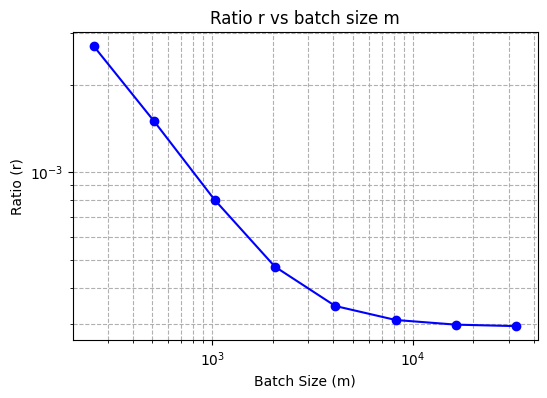

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/ishitak/.netrc.


sigma = 0.00553659071448513


Training...


wandb: Currently logged in as: ishita49 (IITB-CMInDS) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


{'input_ids': [30665, 15152, 11, 715, 785, 1537, 3040, 18509, 315, 847, 6668, 3701, 1372, 525, 220, 24, 23, 18, 22], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'special_tokens_mask': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


  0%|          | 0/489 [00:00<?, ?it/s]

FIL=0, Baseline FIL=0 for step=0


... (2 outputs left out)

KeyboardInterrupt: 

Error in callback <bound method _WandbInit._post_run_cell_hook of <wandb.sdk.wandb_init._WandbInit object at 0x7f050303b860>> (for post_run_cell), with arguments args (<ExecutionResult object at 7f05de02ca40, execution_count=21 error_before_exec=None error_in_exec= info=<ExecutionInfo object at 7f041b5fcf80, raw_cell="num_epochs=3
lr=1e-4
batch_size = 16
batch_size_ev.." transformed_cell="num_epochs=3
lr=1e-4
batch_size = 16
batch_size_ev.." store_history=True silent=False shell_futures=True cell_id=vscode-notebook-cell://ssh-remote%2B164.52.204.237/home/ishitak/ssh/run-03/FIL/1.ipynb#X51sdnNjb2RlLXJlbW90ZQ%3D%3D> result=None>,),kwargs {}:


ConnectionResetError: Connection lost

: 

In [ ]:
num_epochs=3
lr=1e-4
batch_size = 16
batch_size_eval=2
sub_batch_size=2
x=[16] # 1,4,16
r=5
ratio=0.005
can='Dear Ram, \nThe last four digits of my credit card number are 9824'
e=[2] #2,8,32
shuffle=False
FIL_Accountant=np.arange(0,49)
# FIL_Base_Accountant=np.arange(0, 49)

for i in e:
    print(f'----------Epsilon={i}----------')
    sigma=-1
    for number in x:
        print(f'----------No. of insertions={number}----------')
        print('Loading the dataset...')
        dataset = prep_dataset(dataset = get_dataset(ratio=0.004))
        print(dataset) 

        print('\n\nTokenizing the dataset...')
        tokenized_datasets = dataset.map(
            tokenize_function, batched=True, remove_columns=["text"]
        )

        print('\n\nGrouping the dataset...')
        tokenized_datasets = tokenized_datasets.map(group_texts, batched=True, fn_kwargs={"canary":can,"num":number,"shuffle":shuffle})
        print(f"Preprocessed data: {tokenized_datasets}")# After grouping, no. of rows in tokenised_datasets might change

        print('\n\nCreating Dataloaders...')
        train_dataloader,eval_dataloader = get_dataloaders(tokenized_datasets=tokenized_datasets,per_device_train_batch_size=batch_size,per_device_eval_batch_size=batch_size_eval,sub_batch_size=sub_batch_size)

        num,max_train_steps = get_steps(train_dataloader=train_dataloader,max_train_steps=None,num_train_epochs=num_epochs)

        if sigma==-1:
            print('\n\nCalculating sigma:')
            sigma = get_sigma(T=max_train_steps,n=num*sub_batch_size/ratio, batch_size=batch_size,ep=i)
            print(f'sigma = {sigma}')

        print('\n\nTraining...')
        wandb.init(project="run-03_FIL_expt-01", name=f'Num={number},epsilon={i}_lr={lr}',entity="ishita49-indian-institute-of-technology-madras")
        fil,base_fil=train_model(r=r,canary=can,train_dataloader=train_dataloader, eval_dataloader=eval_dataloader, learning_rate=lr,num_epoch=num_epochs,T=max_train_steps,batch_size=batch_size,n=num, sub_batch_size=sub_batch_size,sigma=sigma,ep=i)
        # wandb.finish()
        print(fil)
        print(base_fil)

        wandb.init(project="run-03_FIL_expt-01", name=f'FIL Num={number},epsilon={i}',entity="ishita49-indian-institute-of-technology-madras")
        get_FILs(FIL_Accountant,fil,number,'FIL')
        wandb.finish()

        # wandb.init(project="run-03_FIL - No shuffle", name=f'FIL_Base Num={number},epsilon={i} (Test:413)',entity="ishita49-indian-institute-of-technology-madras")
        # get_FILs(FIL_Base_Accountant,base_fil,number,'Baseline FIL')
        # wandb.finish()

        gc.collect()
        torch.cuda.empty_cache()
        device = torch.device("cuda:0")

        model = AutoModelForCausalLM.from_pretrained(
        "Qwen/Qwen2.5-1.5B",
        cache_dir="./qwen25_15b",
        )

        tokenizer = AutoTokenizer.from_pretrained(
        "Qwen/Qwen2.5-1.5B",
        cache_dir="./qwen25_15b",
        )

        tokenizer.pad_token = tokenizer.eos_token
        model.config.pad_token_id = tokenizer.eos_token_id
        model.to(device)